In [ ]:
from IPython.display import display, Markdown

display(Markdown("""
# Lung Cancer Classification Using SVM

**Project:** Machine Learning Classification

**Algorithm:** Support Vector Machine (SVM)

**Dataset:** Lung Cancer Dataset
"""))


# Lung Cancer Classification Using SVM

**Project:** Machine Learning Classification

**Algorithm:** Support Vector Machine (SVM)

**Dataset:** Lung Cancer Dataset


# Part 1 — Data Loading and Exploratory Data Analysis (EDA)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (3000, 16)


In [ ]:
df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN,LUNG_CANCER
0,M,65,1,1,1,2,2,1,2,2,2,2,2,2,1,NO
1,F,55,1,2,2,1,1,2,2,2,1,1,1,2,2,NO
2,F,78,2,2,1,1,1,2,1,2,1,1,2,1,1,YES
3,M,60,2,1,1,1,2,1,2,1,1,2,1,2,2,YES
4,F,80,1,1,2,1,1,2,1,2,1,1,1,1,2,NO


In [ ]:
# Identify the target column
target = "LUNG_CANCER"

# Identify the feature columns
features = [col for col in df.columns if col != target]

print("Features:")
for feature in features:
    print("-", feature)

print("\nTarget:")
print(target)

print("\nNumber of Features:", len(features))

Features:
- GENDER
- AGE
- SMOKING
- YELLOW_FINGERS
- ANXIETY
- PEER_PRESSURE
- CHRONIC_DISEASE
- FATIGUE
- ALLERGY
- WHEEZING
- ALCOHOL_CONSUMING
- COUGHING
- SHORTNESS_OF_BREATH
- SWALLOWING_DIFFICULTY
- CHEST_PAIN

Target:
LUNG_CANCER

Number of Features: 15


In [ ]:
print("Number of Samples:", df.shape[0])
print("Number of Features:", len(features))
print("Number of Target Variables:", 1)
print("Total Number of Columns:", df.shape[1])

Number of Samples: 3000
Number of Features: 15
Number of Target Variables: 1
Total Number of Columns: 16


In [ ]:
import seaborn as sns

sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [ ]:
target_col = "LUNG_CANCER"

# Columns stored as numerical data types
numeric_dtype_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

# Columns stored as text or categorical data types
text_categorical_cols = df.select_dtypes(
    exclude=np.number
).columns.tolist()

# Identify binary categorical columns
binary_cols = [
    col for col in numeric_dtype_cols
    if col != target_col and df[col].nunique() == 2
]

# Identify continuous numerical features
numerical_cols = [
    col for col in numeric_dtype_cols
    if col not in binary_cols and col != target_col
]

# Combine categorical features
categorical_cols = [
    col for col in text_categorical_cols
    if col != target_col
] + binary_cols

print("Numerical Features:")
print(numerical_cols)

print("\nCategorical Features:")
print(categorical_cols)

print("\nBinary Features:")
print(binary_cols)

print("\nTarget Variable:")
print(target_col)

Numerical Features:
['AGE']

Categorical Features:
['GENDER', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH', 'SWALLOWING_DIFFICULTY', 'CHEST_PAIN']

Binary Features:
['SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH', 'SWALLOWING_DIFFICULTY', 'CHEST_PAIN']

Target Variable:
LUNG_CANCER


In [ ]:
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
AGE,3000.0,55.169,14.723746,30.0,42.0,55.0,68.0,80.0


In [ ]:
class_counts = df[target_col].value_counts()

print(class_counts)

LUNG_CANCER
YES    1518
NO     1482
Name: count, dtype: int64


In [ ]:
class_percentages = (
    df[target_col].value_counts(normalize=True) * 100
)

print(class_percentages.round(2))

LUNG_CANCER
YES    50.6
NO     49.4
Name: proportion, dtype: float64


In [ ]:
target_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

display(target_summary)

,Count,Percentage
LUNG_CANCER,,
YES,1518,50.6
NO,1482,49.4


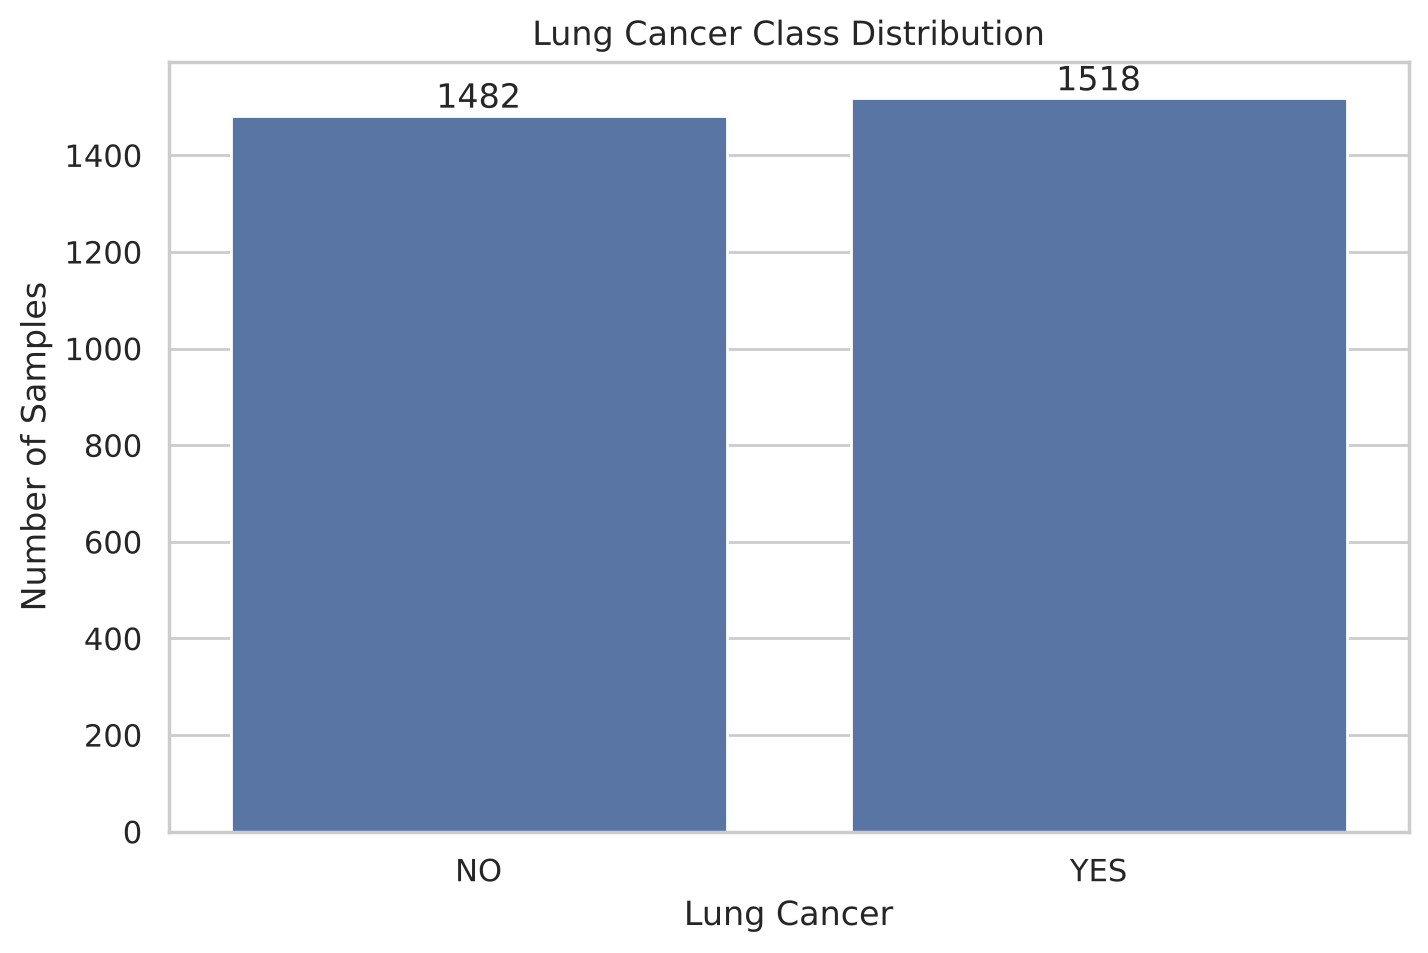

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target_col,
    order=["NO", "YES"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Lung Cancer Class Distribution")
plt.xlabel("Lung Cancer")
plt.ylabel("Number of Samples")

plt.show()

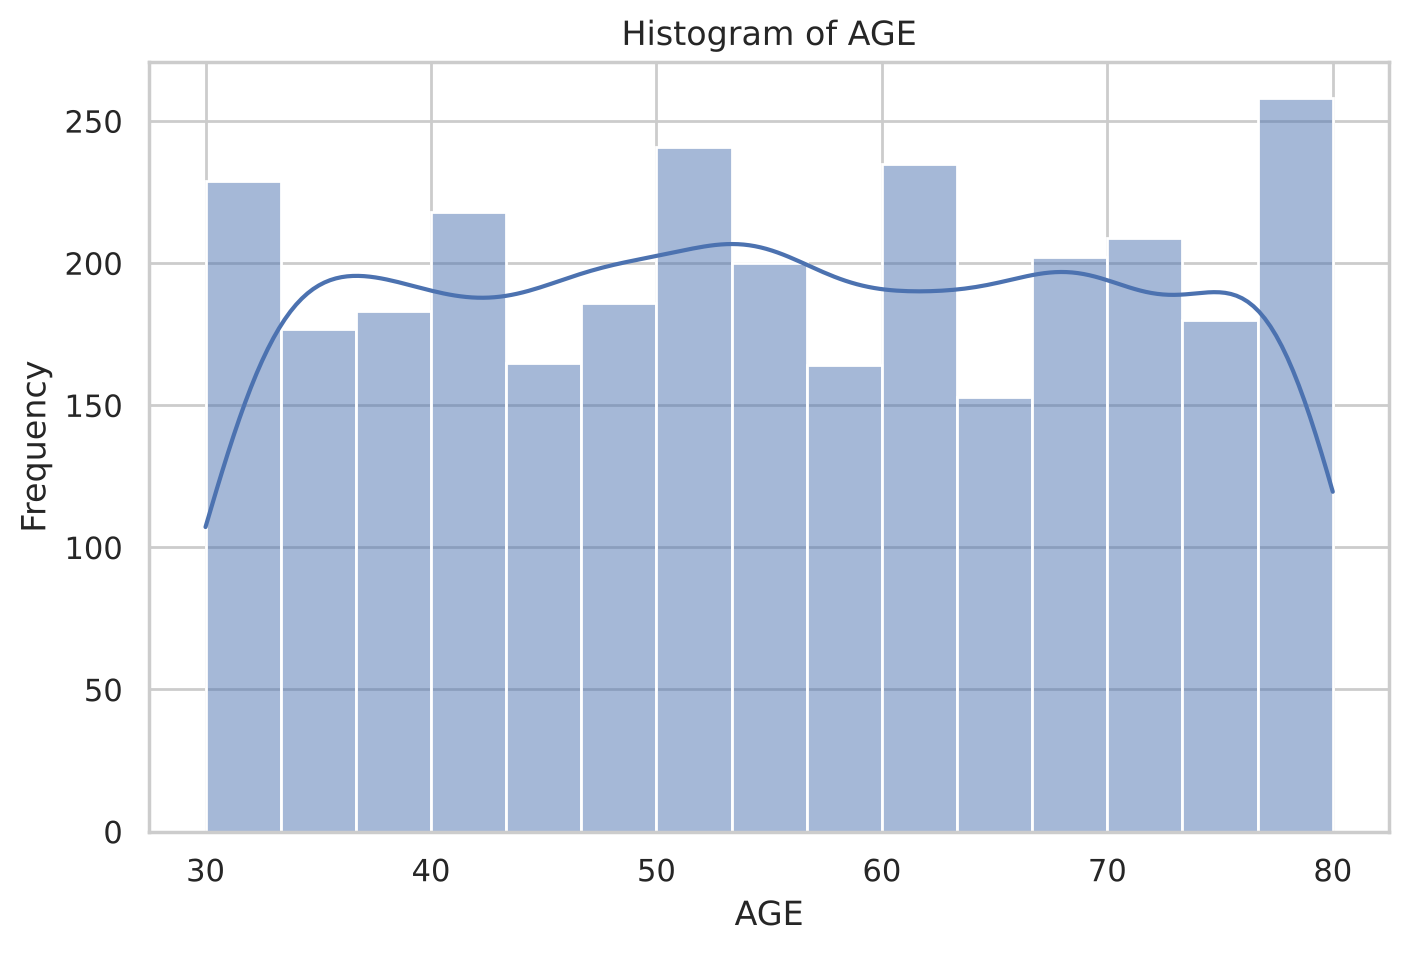

In [ ]:
for col in numerical_cols:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=col,
        bins=15,
        kde=True
    )

    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

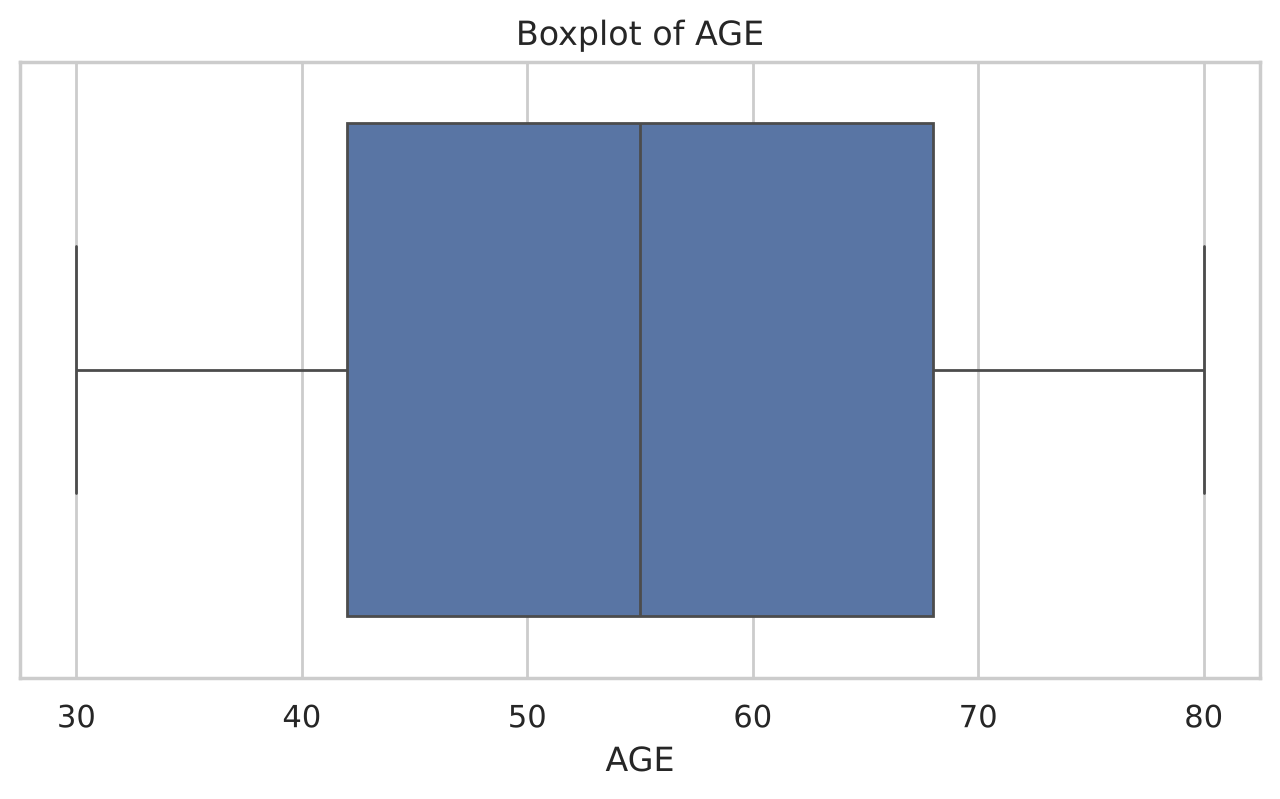

In [ ]:
for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

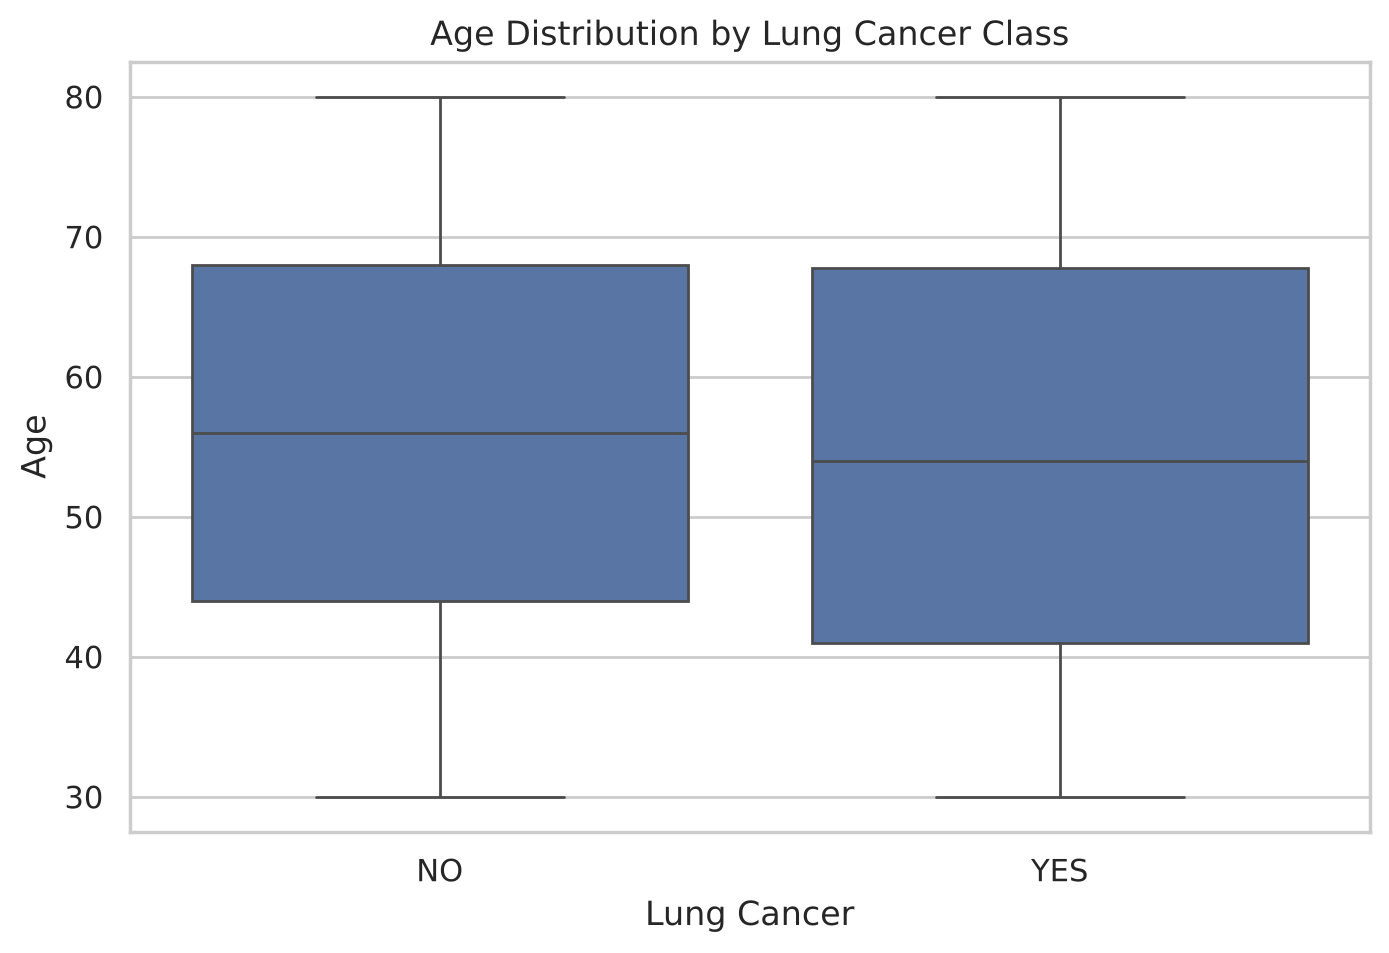

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x=target_col,
    y="AGE",
    order=["NO", "YES"]
)

plt.title("Age Distribution by Lung Cancer Class")
plt.xlabel("Lung Cancer")
plt.ylabel("Age")

plt.show()

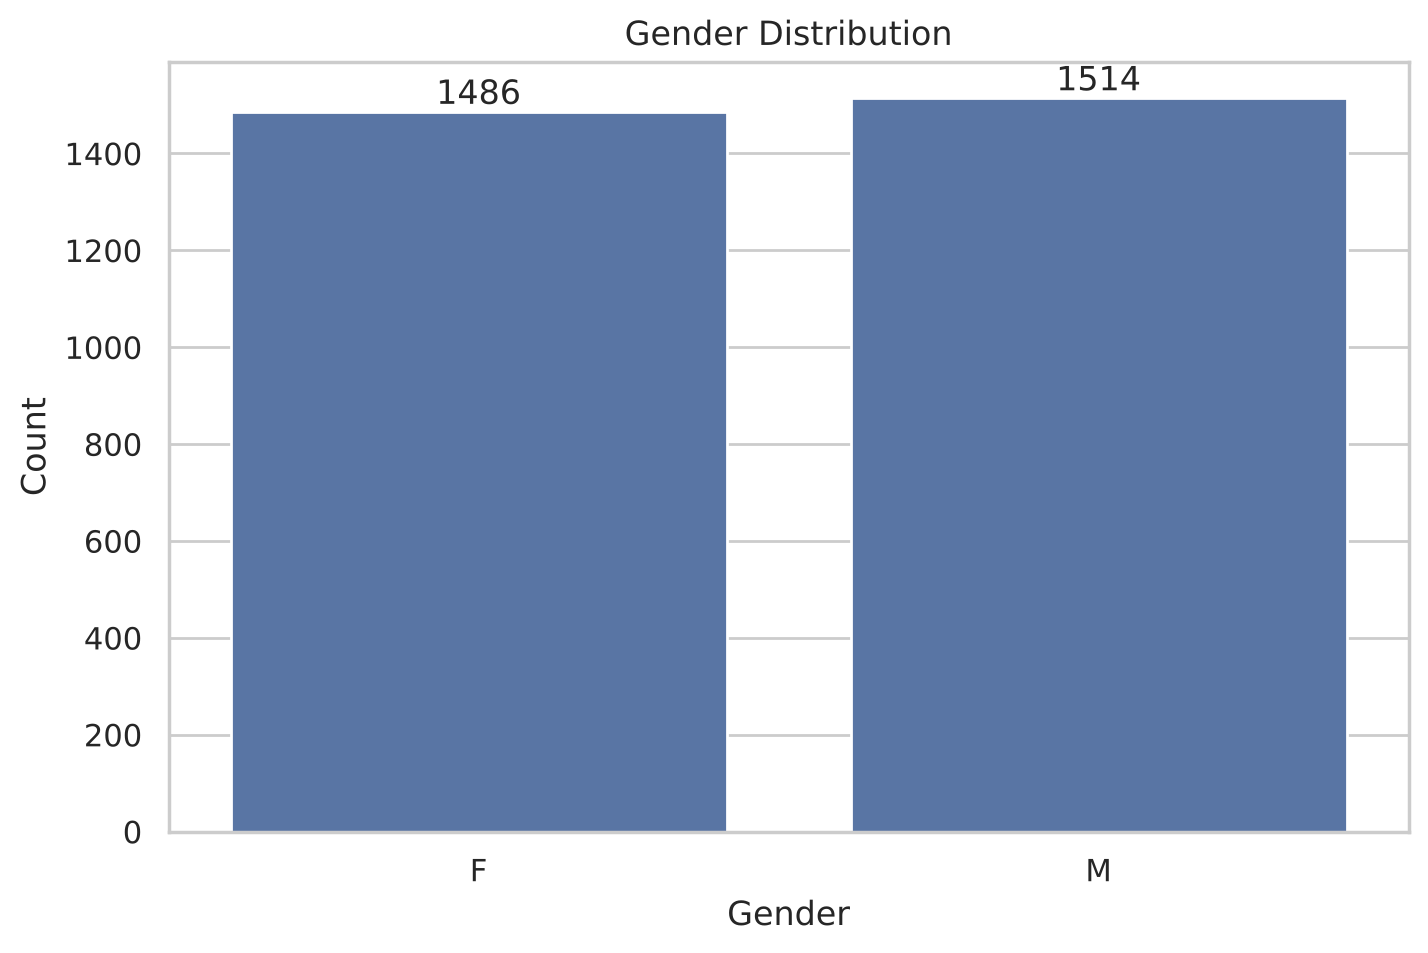

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="GENDER",
    order=["F", "M"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

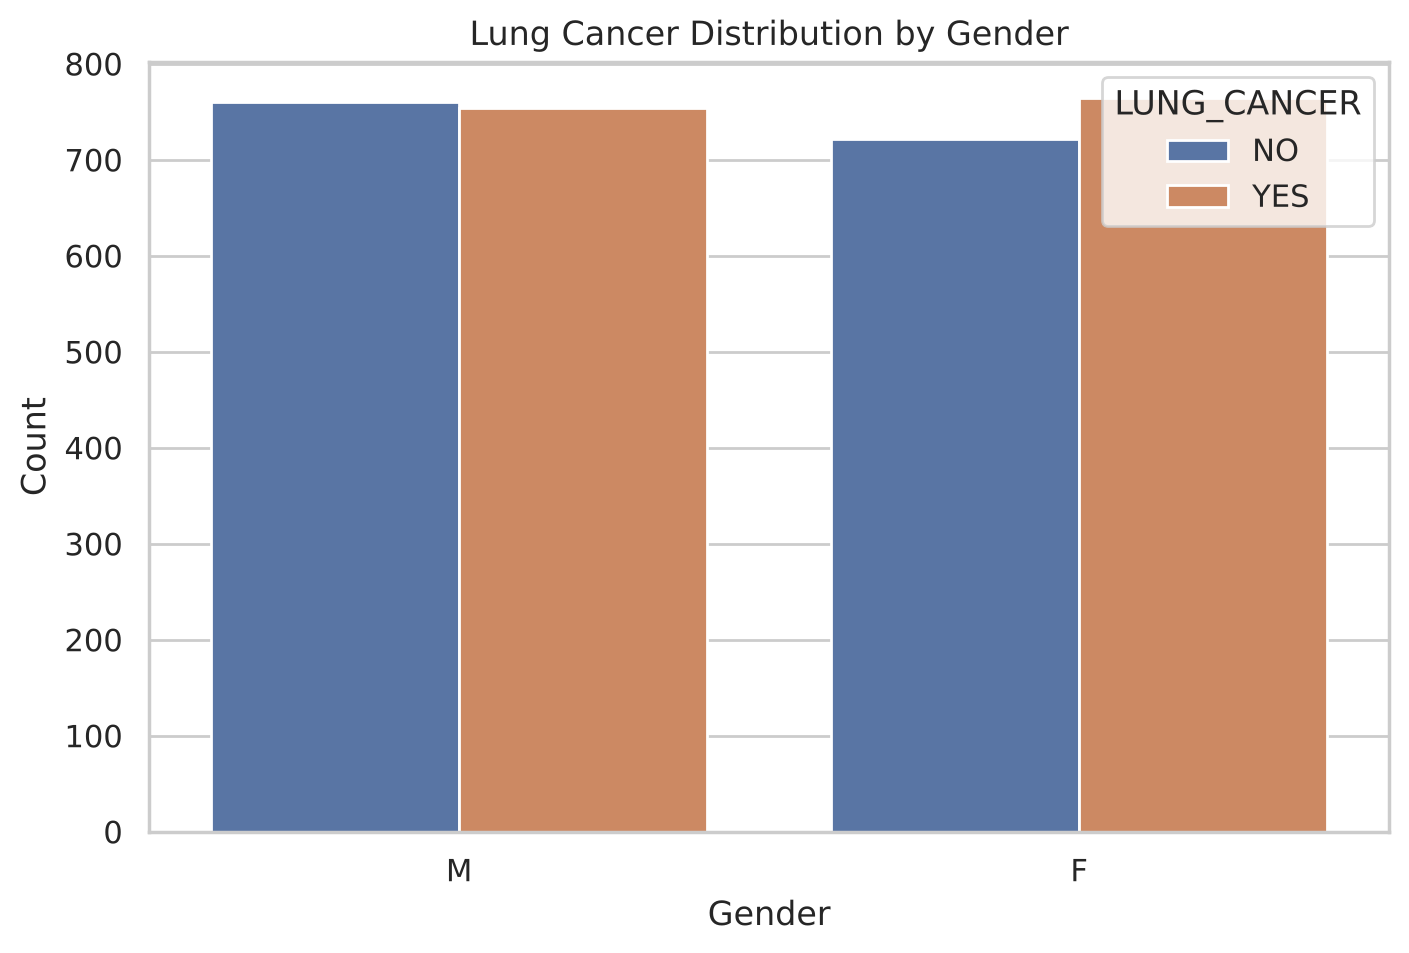

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="GENDER",
    hue=target_col
)

plt.title("Lung Cancer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

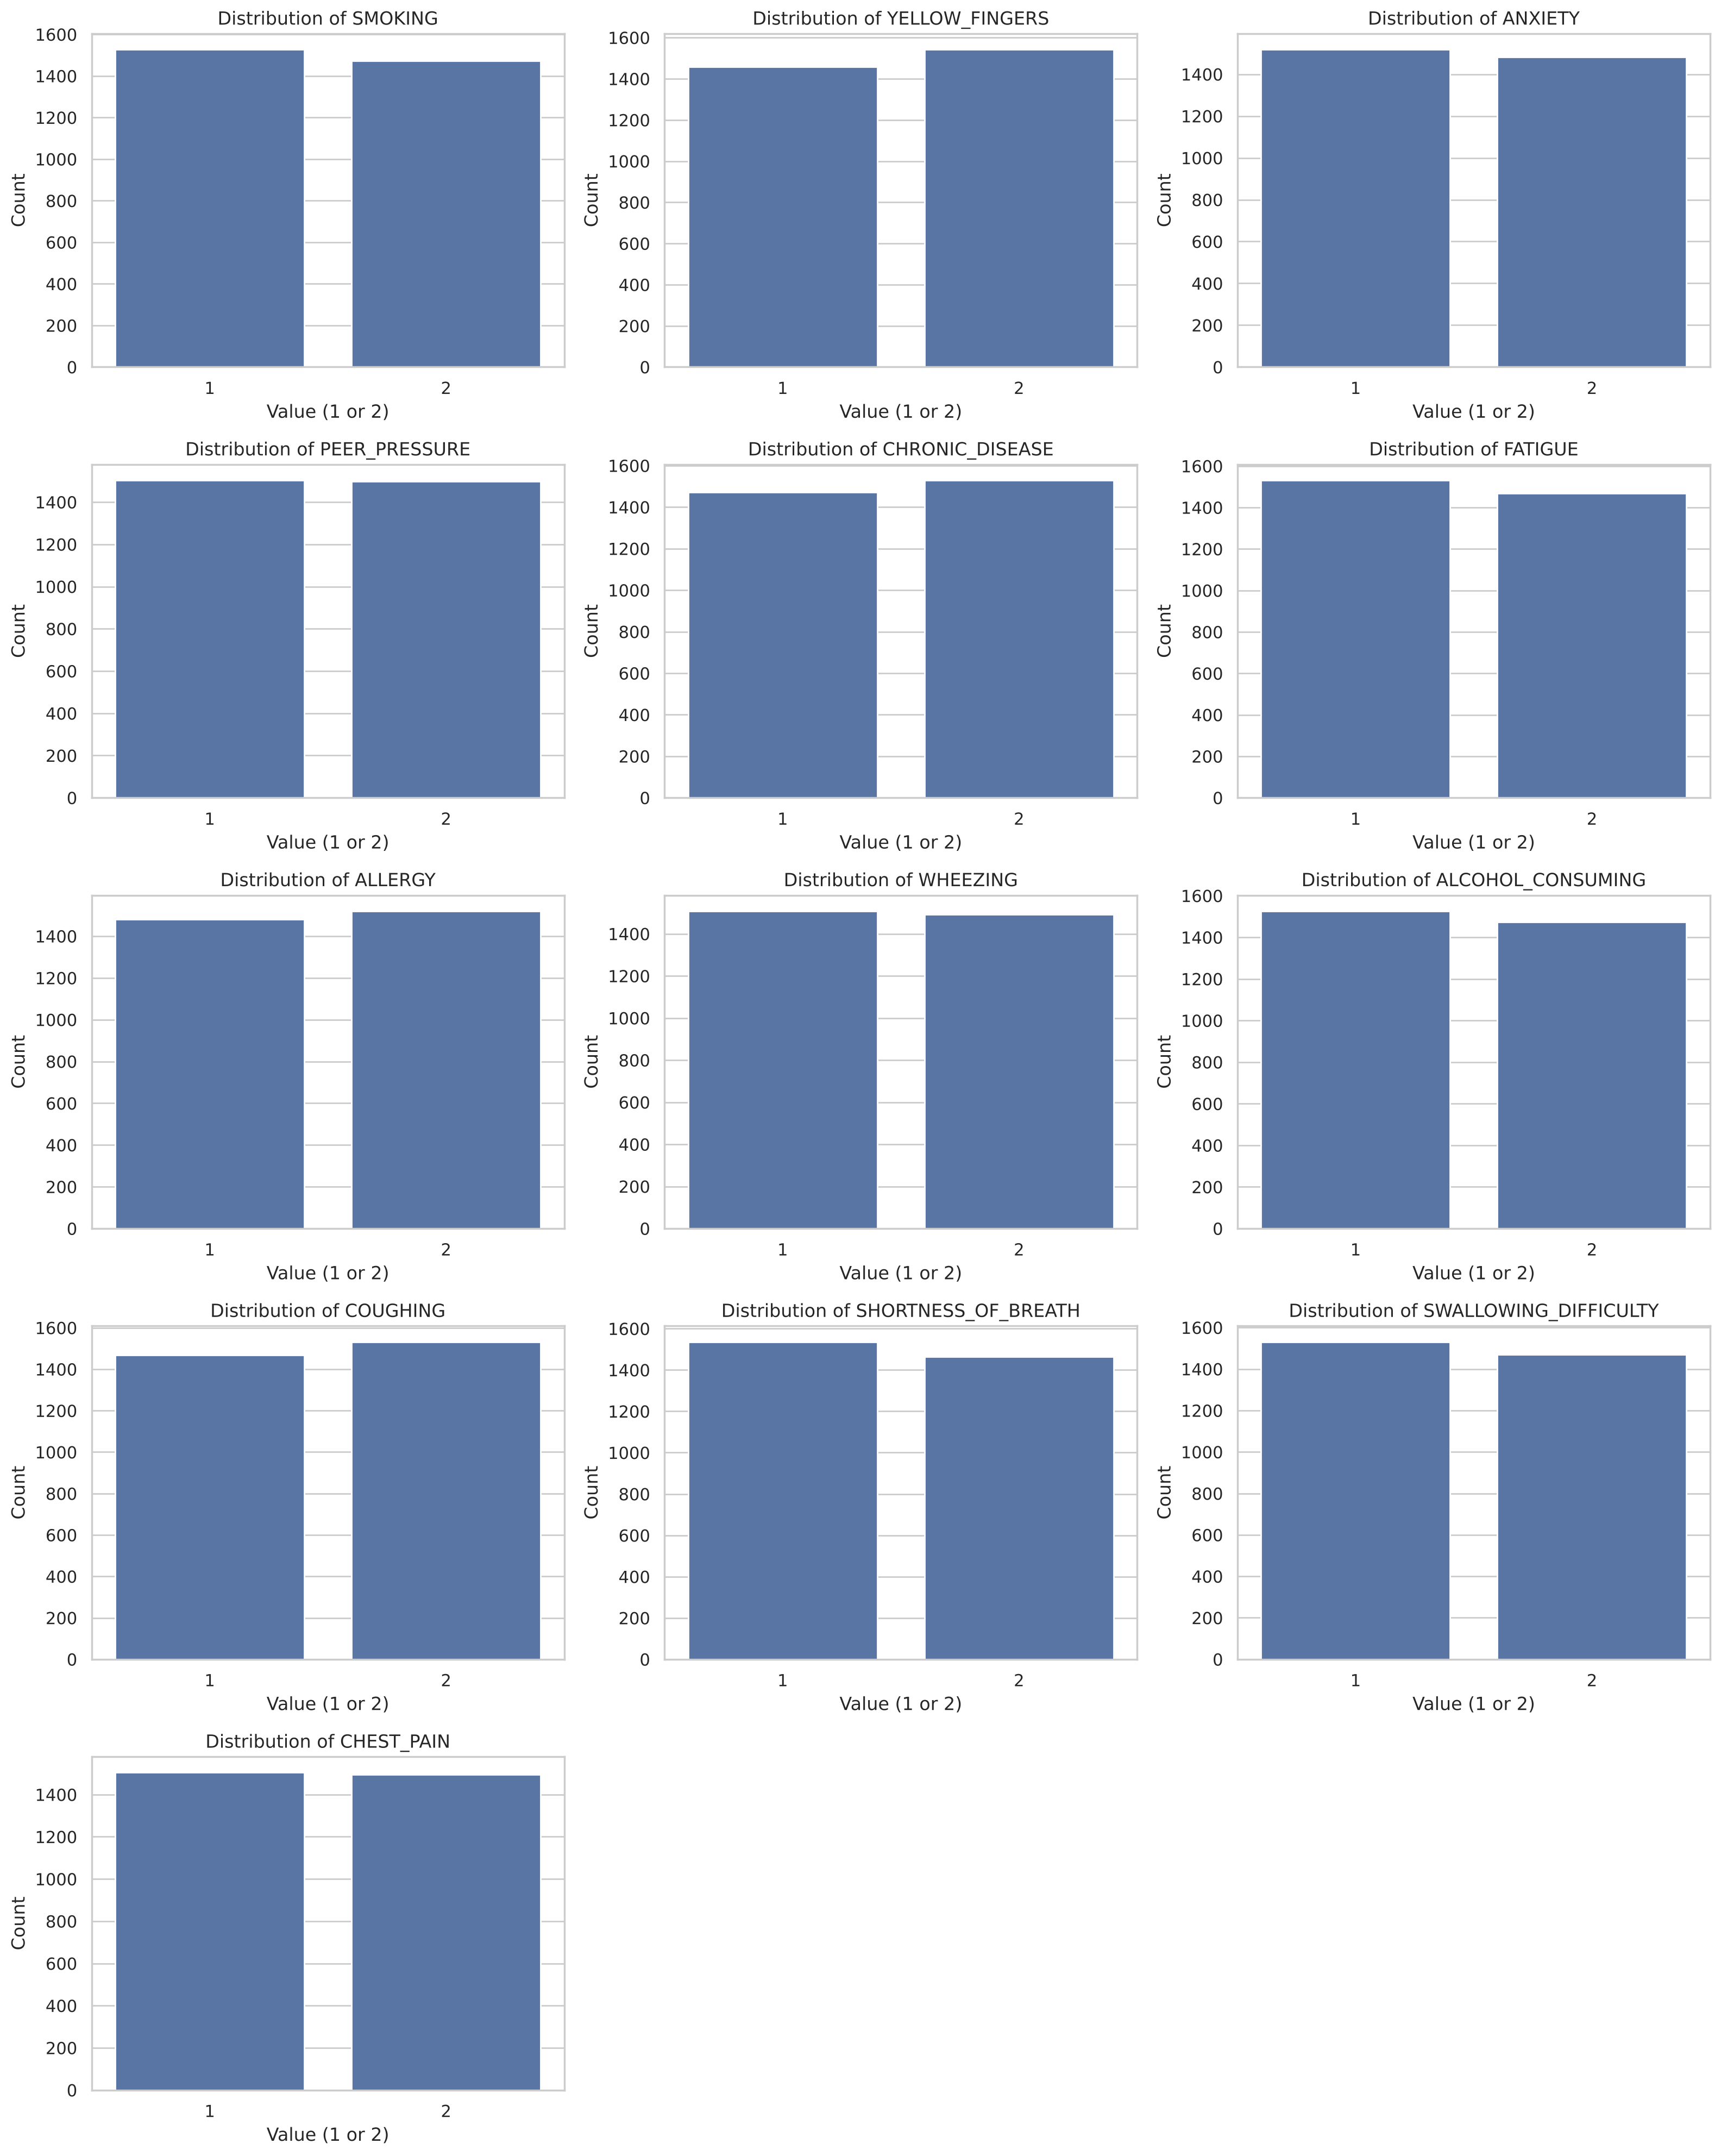

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(binary_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(binary_cols):

    ax = sns.countplot(
        data=df,
        x=col,
        order=[1, 2],
        ax=axes[i]
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Value (1 or 2)")
    ax.set_ylabel("Count")

for j in range(len(binary_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

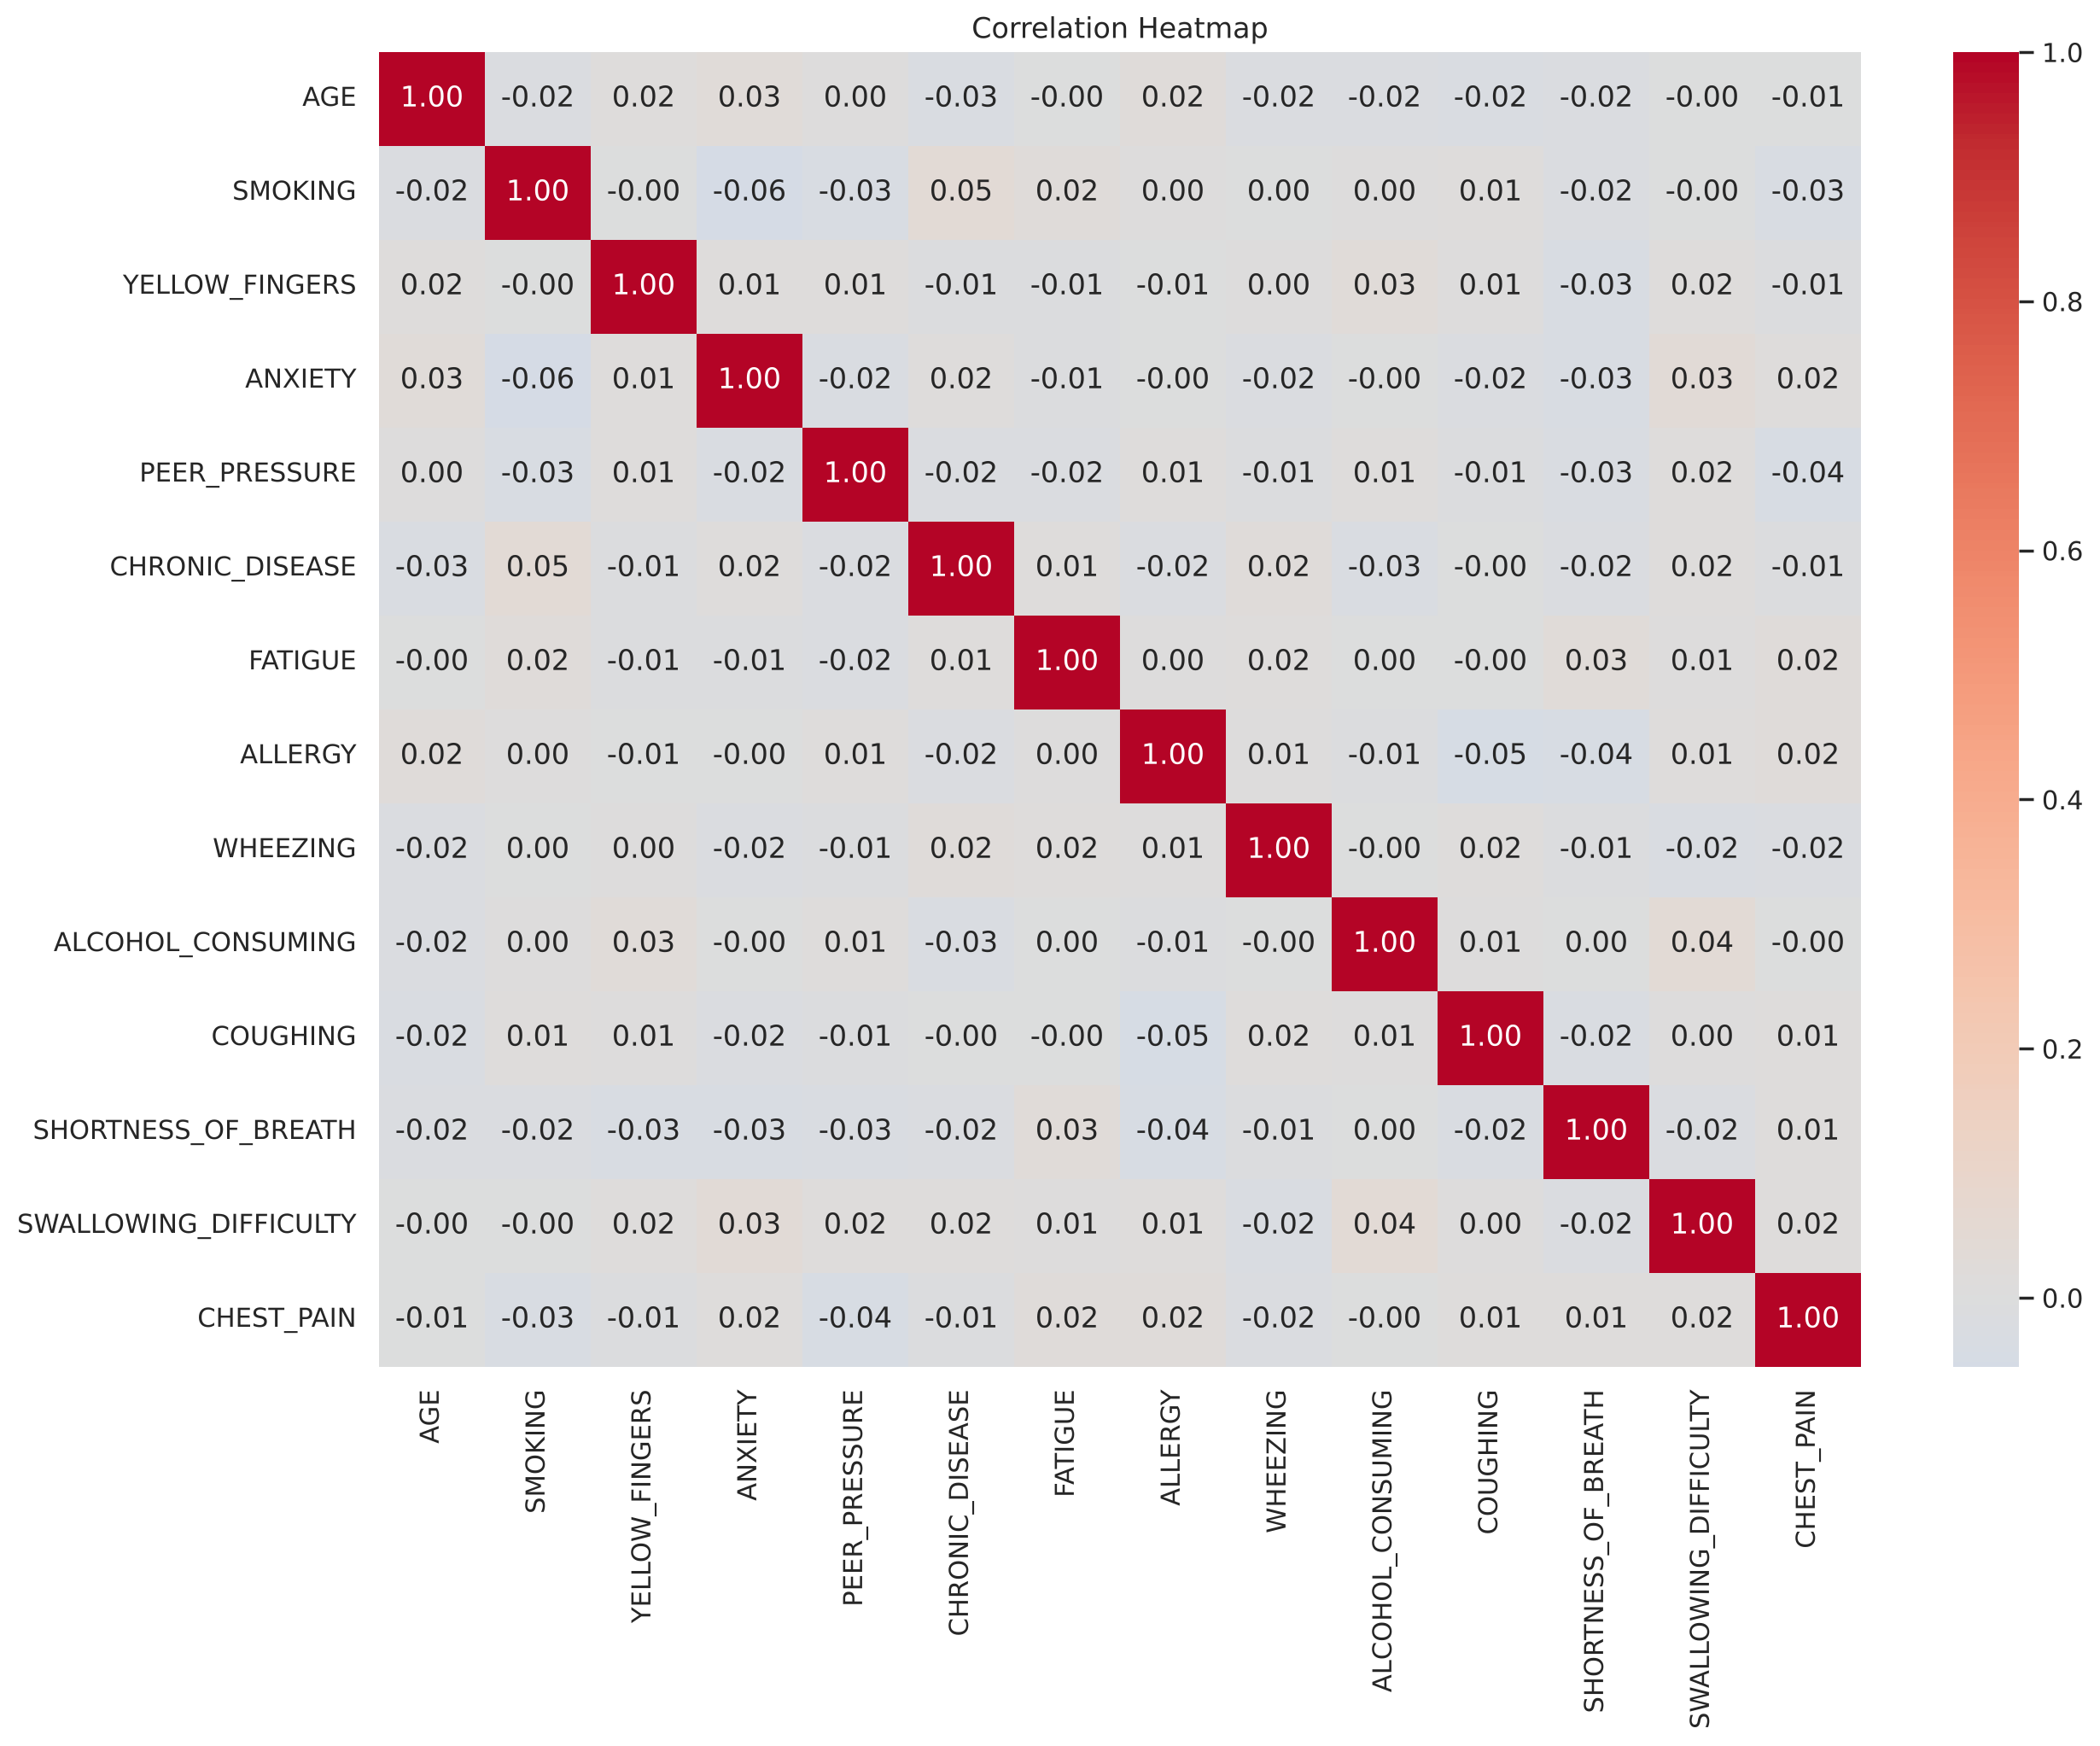

In [ ]:
correlation = df[numeric_dtype_cols].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

# Part 2 — Data Preprocessing and Train/Test Split

## Student 3 — Data Preprocessing and Train/Test Split (for SVM)

**Shared strategy (agreed with the team):**
1. Remove duplicate rows before splitting.
2. Encode the target: NO -> 0, YES -> 1.
3. Stratified 80/20 split with a fixed seed (random_state = 42).
4. Fit imputers, encoders and the scaler on the TRAINING set only.
5. Transform the test set with the already-fitted preprocessor.
6. Share X_train, X_test, y_train, y_test with Students 4 and 5.

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "LUNG_CANCER"
OUTPUT_DIR = "split_data"

df = pd.read_csv("dataset.csv")
print("Dataset shape:", df.shape)

Dataset shape: (3000, 16)


## 1. Data quality: missing values and duplicates

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", int(df.isnull().sum().sum()))

n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nDuplicate rows removed: {n_dup}")
print("Shape after cleaning:", df.shape)

Missing values per column:
GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC_DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL_CONSUMING        0
COUGHING                 0
SHORTNESS_OF_BREATH      0
SWALLOWING_DIFFICULTY    0
CHEST_PAIN               0
LUNG_CANCER              0
dtype: int64

Total missing values: 0

Duplicate rows removed: 2
Shape after cleaning: (2998, 16)


## 2. Feature groups and target encoding

In [ ]:
NUMERICAL_COLS = ["AGE"]                      # continuous -> impute + scale
TEXT_CAT_COLS = ["GENDER"]                    # text (F/M) -> impute + encode
BINARY_COLS = [                               # coded 1 = NO, 2 = YES -> impute + encode
    "SMOKING", "YELLOW_FINGERS", "ANXIETY", "PEER_PRESSURE",
    "CHRONIC_DISEASE", "FATIGUE", "ALLERGY", "WHEEZING",
    "ALCOHOL_CONSUMING", "COUGHING", "SHORTNESS_OF_BREATH",
    "SWALLOWING_DIFFICULTY", "CHEST_PAIN",
]
FEATURES = NUMERICAL_COLS + TEXT_CAT_COLS + BINARY_COLS

X = df[FEATURES].copy()
y = df[TARGET].str.strip().str.upper().map({"NO": 0, "YES": 1}).astype(int)

print("X shape:", X.shape)
print("Target distribution:\n", y.value_counts().rename({0: "NO (0)", 1: "YES (1)"}))

X shape: (2998, 15)
Target distribution:
 LUNG_CANCER
YES (1)    1517
NO (0)     1481
Name: count, dtype: int64


## 3. Train/test split (stratified, fixed seed)
The split happens BEFORE any fitting, so the test set never influences preprocessing.

In [ ]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train:", X_train_raw.shape, " Test:", X_test_raw.shape)
print(pd.DataFrame({
    "Full (%)":  y.value_counts(normalize=True) * 100,
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Test (%)":  y_test.value_counts(normalize=True) * 100,
}).rename(index={0: "NO", 1: "YES"}).round(2))

Train: (2398, 15)  Test: (600, 15)
             Full (%)  Train (%)  Test (%)
LUNG_CANCER                               
YES              50.6      50.58     50.67
NO               49.4      49.42     49.33


## 4. Preprocessing pipeline
- **AGE**: median imputation + StandardScaler (SVM is distance-based, so AGE 30–80
  would otherwise dominate the 0/1 features).
- **GENDER**: most-frequent imputation + encoding (F = 0, M = 1).
- **Binary symptoms**: most-frequent imputation + encoding (1 -> 0, 2 -> 1).

In [ ]:
def build_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore",
                                  sparse_output=False)),
    ])
    return ColumnTransformer(
        [
            ("num", numeric, NUMERICAL_COLS),
            ("gender", categorical, TEXT_CAT_COLS),
            ("binary", categorical, BINARY_COLS),
        ],
        verbose_feature_names_out=False,
    )

preprocessor = build_preprocessor()

## 5. Fit on TRAIN only, then transform train and test

In [ ]:
preprocessor.fit(X_train_raw)                       # learns from training data only

feature_names = [n[:-2] if n.endswith("_2") else n  # "SMOKING_2" -> "SMOKING"
                 for n in preprocessor.get_feature_names_out()]

X_train = pd.DataFrame(preprocessor.transform(X_train_raw),
                       columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(preprocessor.transform(X_test_raw),
                      columns=feature_names, index=X_test_raw.index)

scaler = preprocessor.named_transformers_["num"].named_steps["scaler"]
print(f"AGE scaler (fitted on train): mean = {scaler.mean_[0]:.2f}, std = {scaler.scale_[0]:.2f}")
print(f"Scaled AGE  train: mean = {X_train['AGE'].mean():.3f}, std = {X_train['AGE'].std():.3f}")
print(f"Scaled AGE  test : mean = {X_test['AGE'].mean():.3f}, std = {X_test['AGE'].std():.3f}")
X_train.head()

AGE scaler (fitted on train): mean = 54.97, std = 14.69
Scaled AGE  train: mean = 0.000, std = 1.000
Scaled AGE  test : mean = 0.069, std = 1.012


,AGE,GENDER_M,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC_DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL_CONSUMING,COUGHING,SHORTNESS_OF_BREATH,SWALLOWING_DIFFICULTY,CHEST_PAIN
282,-1.155311,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
509,1.568078,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
1486,-1.563819,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
384,1.431909,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0
209,-0.951057,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0


## 6. Final checks

In [ ]:
assert X_train.isnull().sum().sum() == 0 and X_test.isnull().sum().sum() == 0
assert list(X_train.columns) == list(X_test.columns)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert set(np.unique(X_train.drop(columns="AGE"))) <= {0.0, 1.0}
print("All checks passed: no missing values, same columns, no shared rows, binary features are 0/1.")
print("X_train:", X_train.shape, "| X_test:", X_test.shape,
      "| y_train:", y_train.shape, "| y_test:", y_test.shape)

All checks passed: no missing values, same columns, no shared rows, binary features are 0/1.
X_train: (2398, 15) | X_test: (600, 15) | y_train: (2398,) | y_test: (600,)


## 7. Save

In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
X_train.to_csv(f"{OUTPUT_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{OUTPUT_DIR}/X_test.csv", index=False)
y_train.to_frame(TARGET).to_csv(f"{OUTPUT_DIR}/y_train.csv", index=False)
y_test.to_frame(TARGET).to_csv(f"{OUTPUT_DIR}/y_test.csv", index=False)
X_train_raw.to_csv(f"{OUTPUT_DIR}/X_train_raw.csv", index=False)   # for GridSearchCV pipelines
X_test_raw.to_csv(f"{OUTPUT_DIR}/X_test_raw.csv", index=False)
joblib.dump(preprocessor, f"{OUTPUT_DIR}/preprocessor.joblib")

print("Saved:", sorted(os.listdir(OUTPUT_DIR)))

Saved: ['X_test.csv', 'X_test_raw.csv', 'X_train.csv', 'X_train_raw.csv', 'preprocessor.joblib', 'y_test.csv', 'y_train.csv']
